<a href="https://colab.research.google.com/github/miso88oup/image-caption-generator/blob/main/notebooks/03_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Caption Generator — Training

CNN–LSTM decoder trained separately on features from each encoder (VGG16, ResNet50, InceptionV3), using identical hyperparameters. Each encoder is trained with three random seeds to measure run-to-run variation.

The image feature vector initialises the LSTM's hidden and cell states. The LSTM then predicts each next word from the words before it (teacher forcing).

## 1. Setup

In [3]:
import os
import json
import pickle

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/image-caption-project'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
FEATURES_DIR = os.path.join(PROJECT_DIR, 'features')
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
with open(os.path.join(DATA_DIR, 'captions_clean.json')) as f:
    captions = json.load(f)
with open(os.path.join(DATA_DIR, 'splits.json')) as f:
    splits = json.load(f)
with open(os.path.join(DATA_DIR, 'vocab.json')) as f:
    vocab = json.load(f)

word2idx = vocab['word2idx']
vocab_size = vocab['vocab_size']
max_length = vocab['max_length']

print('Vocabulary size:', vocab_size)
print('Max caption length:', max_length)

Vocabulary size: 2528
Max caption length: 38


## 2. Hyperparameters

In [5]:
EMBED_DIM = 256
UNITS = 512
DROPOUT = 0.5
BATCH_SIZE = 64
LEARNING_RATE = 5e-4
EPOCHS = 30
PATIENCE = 3
SEEDS = [42, 7, 123]

ENCODERS = ['vgg16', 'resnet50', 'inceptionv3']

## 3. Training Data

Each caption is padded to `max_length`. Input = caption without the last word, target = caption shifted by one word. Padding positions get zero weight in the loss.

In [6]:
def encode(caption):
    return [word2idx.get(w, 1) for w in caption.split()]


def build_sequences(image_names):
    image_ids, seqs = [], []
    for i, img in enumerate(image_names):
        for cap in captions[img]:
            image_ids.append(i)
            seqs.append(encode(cap))
    seqs = keras.utils.pad_sequences(seqs, maxlen=max_length, padding='post')
    x = seqs[:, :-1]
    y = seqs[:, 1:]
    w = (y != 0).astype('float32')
    return np.array(image_ids), x, y, w


def make_dataset(features, image_names, shuffle, seed=0):
    feat_matrix = tf.constant(np.stack([features[img] for img in image_names]), dtype=tf.float32)
    image_ids, x, y, w = build_sequences(image_names)

    ds = tf.data.Dataset.from_tensor_slices((image_ids, x, y, w))
    if shuffle:
        ds = ds.shuffle(len(x), seed=seed)
    ds = ds.map(lambda i, x, y, w: ((tf.gather(feat_matrix, i), x), y, w))
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


image_ids, x, y, w = build_sequences(splits['train'][:1])
print('Input :', x[0][:12])
print('Target:', y[0][:12])

Input : [2100    2  211  619 1105 1818   16    2 2477  619 1079 2252]
Target: [   2  211  619 1105 1818   16    2 2477  619 1079 2252 2008]


## 4. Model

In [7]:
def build_model(feature_dim):
    image_input = keras.Input(shape=(feature_dim,), name='image_features')
    caption_input = keras.Input(shape=(None,), dtype='int32', name='caption')

    img = layers.BatchNormalization()(image_input)
    img = layers.Dropout(DROPOUT)(img)
    h0 = layers.Dense(UNITS, activation='tanh', name='init_h')(img)
    c0 = layers.Dense(UNITS, activation='tanh', name='init_c')(img)

    emb = layers.Embedding(vocab_size, EMBED_DIM, mask_zero=True, name='embedding')(caption_input)
    emb = layers.Dropout(DROPOUT)(emb)
    seq = layers.LSTM(UNITS, return_sequences=True, name='lstm')(emb, initial_state=[h0, c0])
    seq = layers.Dropout(DROPOUT)(seq)
    output = layers.Dense(vocab_size, activation='softmax', name='next_word')(seq)

    model = keras.Model([image_input, caption_input], output)
    model.compile(
        optimizer=keras.optimizers.Adam(LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        weighted_metrics=['accuracy'],
    )
    return model


build_model(2048).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 2048)      │      8,192 │ image_features[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 256) │    647,168 │ caption[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, None, 256) │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ init_h (Dense)      │ (None, 512)       │  1,049,088 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ init_c (Dense)      │ (None, 512)       │  1,049,088 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, None, 512) │  1,574,912 │ dropout_1[0][0],  │
│                     │                   │            │ init_h[0][0],     │
│                     │                   │            │ init_c[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, None, 512) │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word (Dense)   │ (None, None,      │  1,296,864 │ dropout_2[0][0]   │
│                     │ 2528)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,625,312 (21.46 MB)

 Trainable params: 5,621,216 (21.44 MB)

 Non-trainable params: 4,096 (16.00 KB)

## 5. Train

3 encoders × 3 seeds = 9 runs with identical settings. Early stopping keeps the weights with the lowest validation loss. Runs that are already finished are skipped, so this cell can be re-run after a disconnect.

In [8]:
histories = {}

for name in ENCODERS:
    with open(os.path.join(FEATURES_DIR, f'{name}.pkl'), 'rb') as f:
        features = pickle.load(f)
    feature_dim = len(next(iter(features.values())))

    for seed in SEEDS:
        run = f'{name}_seed{seed}'
        model_path = os.path.join(MODELS_DIR, f'{run}.keras')
        history_path = os.path.join(RESULTS_DIR, f'history_{run}.json')
        if os.path.exists(model_path) and os.path.exists(history_path):
            print(f'{run}: already trained')
            with open(history_path) as f:
                histories[run] = json.load(f)
            continue

        keras.utils.set_random_seed(seed)
        train_ds = make_dataset(features, splits['train'], shuffle=True, seed=seed)
        val_ds = make_dataset(features, splits['val'], shuffle=False)

        model = build_model(feature_dim)
        callbacks = [
            keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
            keras.callbacks.ModelCheckpoint(model_path, monitor='val_loss', save_best_only=True),
        ]

        print(f'\nTraining {run} (feature size {feature_dim})')
        history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)

        histories[run] = {k: [float(v) for v in vals] for k, vals in history.history.items()}
        with open(history_path, 'w') as f:
            json.dump(histories[run], f)

        del model
        keras.backend.clear_session()

    del features

vgg16_seed42: already trained
vgg16_seed7: already trained
vgg16_seed123: already trained
resnet50_seed42: already trained
resnet50_seed7: already trained
resnet50_seed123: already trained
inceptionv3_seed42: already trained
inceptionv3_seed7: already trained
inceptionv3_seed123: already trained


## 6. Training Summary

In [9]:
rows = []
for name in ENCODERS:
    for seed in SEEDS:
        h = histories[f'{name}_seed{seed}']
        best = int(np.argmin(h['val_loss']))
        rows.append({'Encoder': name, 'Seed': seed, 'Best epoch': best + 1,
                     'Val loss': h['val_loss'][best], 'Val accuracy': h['val_accuracy'][best]})

runs = pd.DataFrame(rows)
runs.to_csv(os.path.join(RESULTS_DIR, 'training_runs.csv'), index=False)

summary = runs.groupby('Encoder', sort=False).agg(
    best_epoch=('Best epoch', 'mean'),
    val_loss_mean=('Val loss', 'mean'), val_loss_std=('Val loss', 'std'),
    val_acc_mean=('Val accuracy', 'mean'), val_acc_std=('Val accuracy', 'std'),
).round(4)
summary

,best_epoch,val_loss_mean,val_loss_std,val_acc_mean,val_acc_std
Encoder,,,,,
vgg16,15.3333,2.6113,0.0018,0.3949,0.0013
resnet50,17.0000,2.5666,0.0031,0.4010,0.0011
inceptionv3,19.0000,2.5549,0.0009,0.4027,0.0003


In [10]:
# seed with the lowest validation loss per encoder (used by the demo)
best_seed = {name: int(runs[runs.Encoder == name].sort_values('Val loss').iloc[0]['Seed']) for name in ENCODERS}
with open(os.path.join(RESULTS_DIR, 'best_seeds.json'), 'w') as f:
    json.dump(best_seed, f)
best_seed

{'vgg16': 42, 'resnet50': 123, 'inceptionv3': 7}

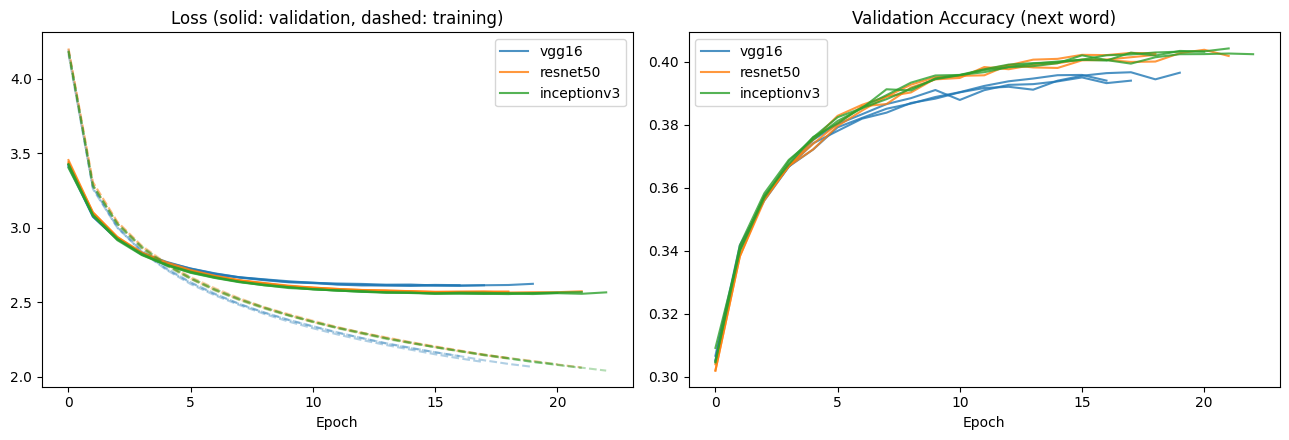

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = dict(zip(ENCODERS, ['tab:blue', 'tab:orange', 'tab:green']))

for name in ENCODERS:
    for i, seed in enumerate(SEEDS):
        h = histories[f'{name}_seed{seed}']
        label = name if i == 0 else None
        axes[0].plot(h['val_loss'], color=colors[name], alpha=0.8, label=label)
        axes[0].plot(h['loss'], color=colors[name], alpha=0.35, linestyle='--')
        axes[1].plot(h['val_accuracy'], color=colors[name], alpha=0.8, label=label)

axes[0].set_title('Loss (solid: validation, dashed: training)')
axes[1].set_title('Validation Accuracy (next word)')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Sample Captions (greedy, seed 42)

In [12]:
idx2word = {i: w for w, i in word2idx.items()}


def greedy_caption(model, feature):
    seq = [word2idx['startseq']]
    for _ in range(max_length):
        probs = model.predict([feature[None, :], np.array([seq])], verbose=0)[0, -1]
        next_id = int(np.argmax(probs))
        if idx2word[next_id] == 'endseq':
            break
        seq.append(next_id)
    return ' '.join(idx2word[i] for i in seq[1:])


test_samples = splits['test'][:3]

for name in ENCODERS:
    model = keras.models.load_model(os.path.join(MODELS_DIR, f'{name}_seed42.keras'))
    with open(os.path.join(FEATURES_DIR, f'{name}.pkl'), 'rb') as f:
        features = pickle.load(f)
    print(f'\n{name}')
    for img in test_samples:
        print(f'  {img}: {greedy_caption(model, features[img])}')
    del model, features
    keras.backend.clear_session()


vgg16
  3385593926_d3e9c21170.jpg: two brown dogs are running in the snow
  2677656448_6b7e7702af.jpg: a dog is playing with a ball in a pool
  311146855_0b65fdb169.jpg: a man in a blue shirt and a blue shirt is holding a <unk> <unk>

resnet50
  3385593926_d3e9c21170.jpg: a brown dog is running through the snow
  2677656448_6b7e7702af.jpg: a small boy is playing in the water
  311146855_0b65fdb169.jpg: a man in a blue shirt and a blue shirt is standing on a street

inceptionv3
  3385593926_d3e9c21170.jpg: a brown dog is running on a snowy path
  2677656448_6b7e7702af.jpg: a dog is jumping into a pool while a man watches
  311146855_0b65fdb169.jpg: a man in a blue shirt is standing in front of a crowd


Using Colab cache for faster access to the 'flickr8k' dataset.


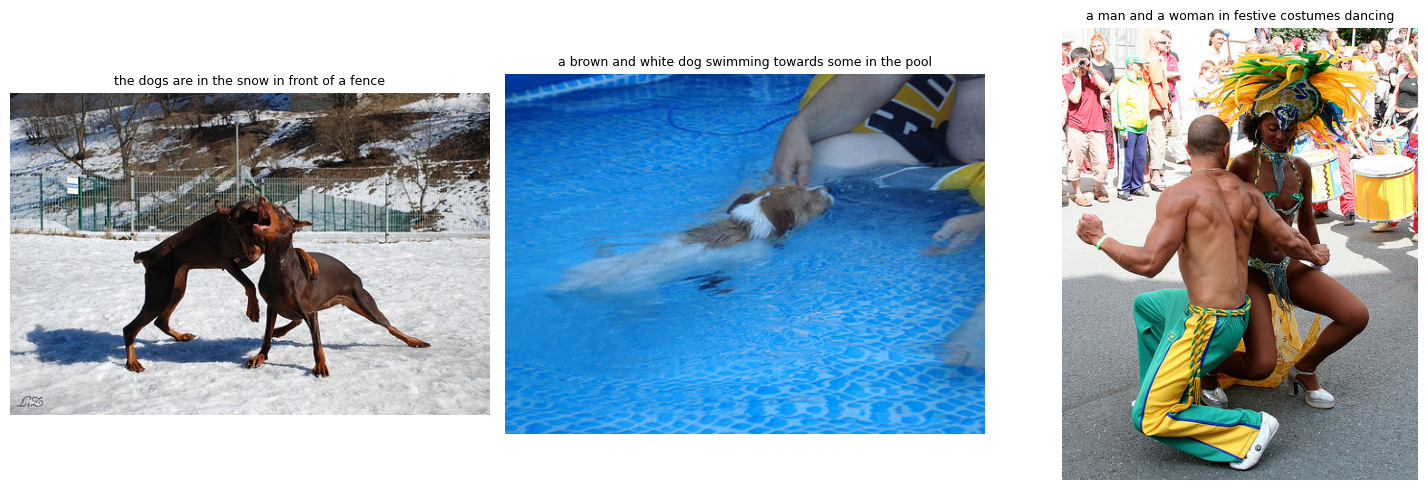

In [13]:
import kagglehub
from PIL import Image

IMAGE_DIR = os.path.join(kagglehub.dataset_download('adityajn105/flickr8k'), 'Images')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img in zip(axes, test_samples):
    ax.imshow(Image.open(os.path.join(IMAGE_DIR, img)))
    ax.set_title(captions[img][0][9:-7], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()